In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pypulseq as pp

print("PyPulseq version:", pp.__version__)
print("Environment is ready!")

PyPulseq version: 1.5.0.post1
Environment is ready!


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pypulseq as pp

# MRI system specifications
system = pp.Opts(
    max_grad=32,
    grad_unit='mT/m',
    max_slew=130,
    slew_unit='T/m/s',
    rf_ringdown_time=20e-6,
    rf_dead_time=100e-6,
    adc_dead_time=10e-6
)

print("MRI system initialized successfully!")

MRI system initialized successfully!


In [5]:
seq = pp.Sequence(system)

print("Sequence object created successfully!")

Sequence object created successfully!


In [7]:
rf, gz, gz_reph = pp.make_sinc_pulse(
    flip_angle=flip_angle,
    duration=2e-3,
    slice_thickness=5e-3,
    apodization=0.5,
    time_bw_product=4,
    delay=system.rf_dead_time,
    system=system,
    return_gz=True
)

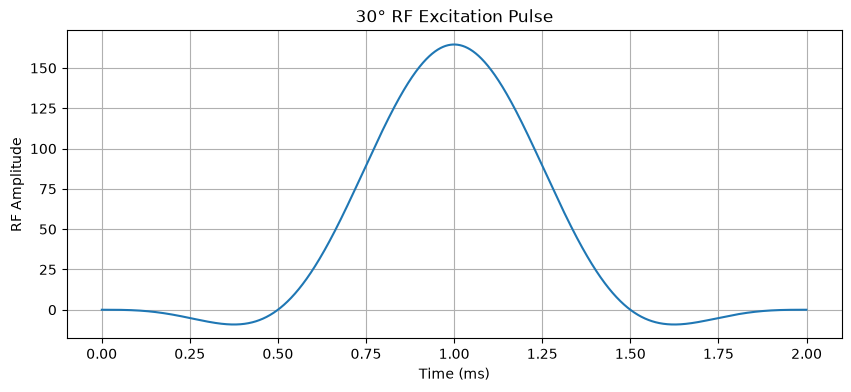

In [8]:
plt.figure(figsize=(10, 4))

plt.plot(
    rf.t * 1e3,
    rf.signal.real
)

plt.xlabel("Time (ms)")
plt.ylabel("RF Amplitude")
plt.title("30° RF Excitation Pulse")
plt.grid(True)

plt.show()


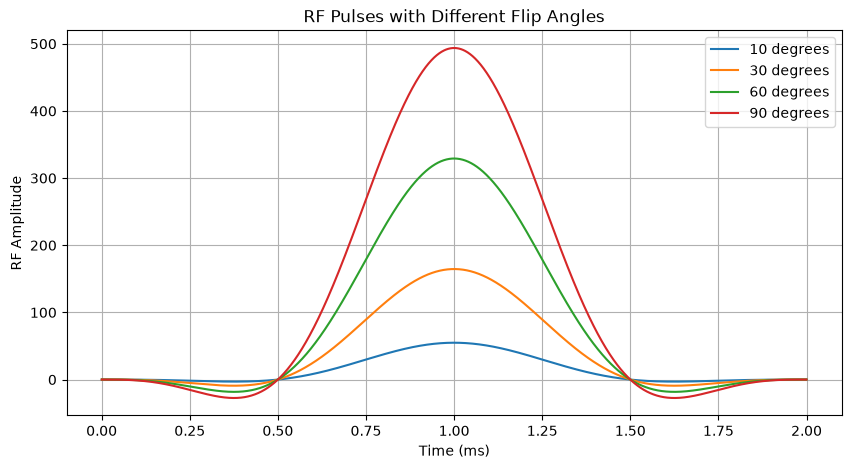

In [9]:
flip_angles = [10, 30, 60, 90]

plt.figure(figsize=(10, 5))

for angle in flip_angles:

    rf_test, _, _ = pp.make_sinc_pulse(
        flip_angle=np.deg2rad(angle),
        duration=2e-3,
        slice_thickness=5e-3,
        apodization=0.5,
        time_bw_product=4,
        delay=system.rf_dead_time,
        system=system,
        return_gz=True
    )

    plt.plot(
        rf_test.t * 1e3,
        rf_test.signal.real,
        label=f'{angle} degrees'
    )

plt.xlabel('Time (ms)')
plt.ylabel('RF Amplitude')
plt.title('RF Pulses with Different Flip Angles')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Recreate RF pulse and slice selection gradient

flip_angle = np.deg2rad(30)

rf, gz, gz_reph = pp.make_sinc_pulse(
    flip_angle=flip_angle,
    duration=2e-3,
    slice_thickness=5e-3,
    apodization=0.5,
    time_bw_product=4,
    delay=system.rf_dead_time,
    system=system,
    return_gz=True
)

print("RF pulse:", rf.type)
print("Gradient:", gz.type)
print("Rephasing gradient:", gz_reph.type)

RF pulse: rf
Gradient: trap
Rephasing gradient: trap


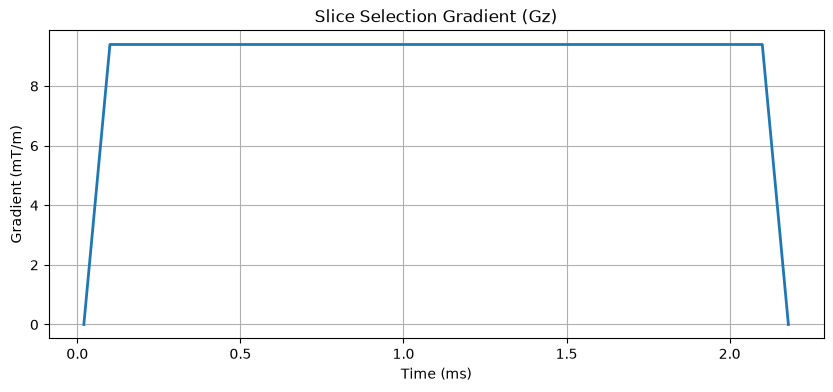

Gradient amplitude: 9.395 mT/m


In [17]:
# Proton gyromagnetic ratio
gamma = 42.576e6  # Hz/T

# Gradient amplitude conversion: Hz/m to mT/m
g_z_mTm = (gz.amplitude / gamma) * 1e3

# Gradient timing
t_gz = np.array([
    0,
    gz.rise_time,
    gz.rise_time + gz.flat_time,
    gz.rise_time + gz.flat_time + gz.fall_time
]) + gz.delay

# Gradient waveform
g_z = np.array([
    0,
    g_z_mTm,
    g_z_mTm,
    0
])

# Plot
plt.figure(figsize=(10, 4))

plt.plot(t_gz * 1e3, g_z, linewidth=2)

plt.xlabel("Time (ms)")
plt.ylabel("Gradient (mT/m)")
plt.title("Slice Selection Gradient (Gz)")
plt.grid(True)

plt.show()

print(f"Gradient amplitude: {g_z_mTm:.3f} mT/m")

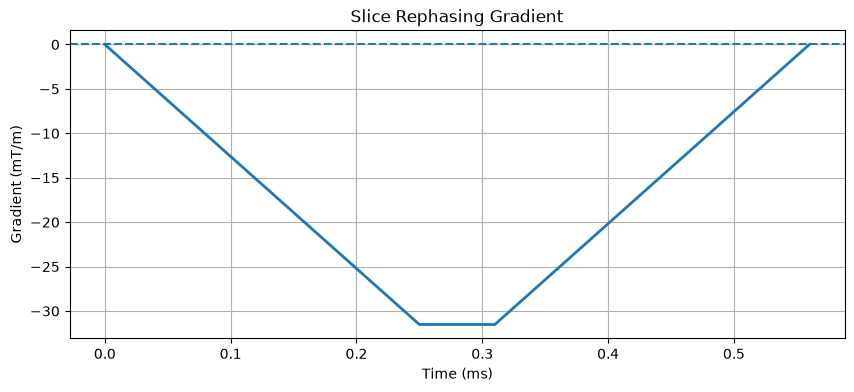

In [18]:
# Proton gyromagnetic ratio
gamma = 42.576e6  # Hz/T

# Rephasing gradient amplitude
g_reph_mTm = (gz_reph.amplitude / gamma) * 1e3

# Gradient timing
t_reph = np.array([
    0,
    gz_reph.rise_time,
    gz_reph.rise_time + gz_reph.flat_time,
    gz_reph.rise_time + gz_reph.flat_time + gz_reph.fall_time
]) + gz_reph.delay

# Gradient waveform
g_reph = np.array([
    0,
    g_reph_mTm,
    g_reph_mTm,
    0
])

# Plot
plt.figure(figsize=(10, 4))

plt.plot(
    t_reph * 1e3,
    g_reph,
    linewidth=2
)

plt.axhline(0, linestyle='--')

plt.xlabel("Time (ms)")
plt.ylabel("Gradient (mT/m)")
plt.title("Slice Rephasing Gradient")
plt.grid(True)

plt.show()

In [19]:
print("Slice selection gradient area:")
print(f"{gz.area:.3f} Hz/m")

print("\nRephasing gradient area:")
print(f"{gz_reph.area:.3f} Hz/m")

print("\nArea ratio:")
print(f"{gz_reph.area / gz.area:.3f}")

Slice selection gradient area:
832.000 Hz/m

Rephasing gradient area:
-416.000 Hz/m

Area ratio:
-0.500
